<a href="https://colab.research.google.com/github/danishsuryarirta-create/Tugas_Akhir/blob/main/Osteoporosis_TA.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [54]:
import numpy as np
import pandas as pd
import warnings
warnings.filterwarnings('ignore')

import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style("whitegrid")
pd.set_option("display.max_columns", None)

## **Input Dataset**

In [55]:
df = pd.read_csv('osteoporosis.csv', keep_default_na=False)
print(f'Shape dataset : {df.shape}')
print(f'Jumlah baris  : {df.shape[0]:,}')
print(f'Jumlah kolom  : {df.shape[1]}')

Shape dataset : (1958, 16)
Jumlah baris  : 1,958
Jumlah kolom  : 16


## **Data Understanding**

### **1. Cek Struktur Data**

In [56]:
print("Dataset berhasil dimuat")
df.head()

Dataset berhasil dimuat


,Id,Age,Gender,Hormonal Changes,Family History,Race/Ethnicity,Body Weight,Calcium Intake,Vitamin D Intake,Physical Activity,Smoking,Alcohol Consumption,Medical Conditions,Medications,Prior Fractures,Osteoporosis
0,1734616,69,Female,Normal,Yes,Asian,Underweight,Low,Sufficient,Sedentary,Yes,Moderate,Rheumatoid Arthritis,Corticosteroids,Yes,1
1,1419098,32,Female,Normal,Yes,Asian,Underweight,Low,Sufficient,Sedentary,No,None,None,None,Yes,1
2,1797916,89,Female,Postmenopausal,No,Caucasian,Normal,Adequate,Sufficient,Active,No,Moderate,Hyperthyroidism,Corticosteroids,No,1
3,1805337,78,Female,Normal,No,Caucasian,Underweight,Adequate,Insufficient,Sedentary,Yes,None,Rheumatoid Arthritis,Corticosteroids,No,1
4,1351334,38,Male,Postmenopausal,Yes,African American,Normal,Low,Sufficient,Active,Yes,None,Rheumatoid Arthritis,None,Yes,1


In [57]:
print("Jumlah baris & kolom :", df.shape)
print("\n=== Info Dataset ===")
df.info()

Jumlah baris & kolom : (1958, 16)

=== Info Dataset ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1958 entries, 0 to 1957
Data columns (total 16 columns):
 #   Column               Non-Null Count  Dtype 
---  ------               --------------  ----- 
 0   Id                   1958 non-null   int64 
 1   Age                  1958 non-null   int64 
 2   Gender               1958 non-null   object
 3   Hormonal Changes     1958 non-null   object
 4   Family History       1958 non-null   object
 5   Race/Ethnicity       1958 non-null   object
 6   Body Weight          1958 non-null   object
 7   Calcium Intake       1958 non-null   object
 8   Vitamin D Intake     1958 non-null   object
 9   Physical Activity    1958 non-null   object
 10  Smoking              1958 non-null   object
 11  Alcohol Consumption  1958 non-null   object
 12  Medical Conditions   1958 non-null   object
 13  Medications          1958 non-null   object
 14  Prior Fractures      1958 non-null   object
 15 

In [58]:
print("\n=== Tipe Data per Kolom ===")
print(df.dtypes)


=== Tipe Data per Kolom ===
Id                      int64
Age                     int64
Gender                 object
Hormonal Changes       object
Family History         object
Race/Ethnicity         object
Body Weight            object
Calcium Intake         object
Vitamin D Intake       object
Physical Activity      object
Smoking                object
Alcohol Consumption    object
Medical Conditions     object
Medications            object
Prior Fractures        object
Osteoporosis            int64
dtype: object


### **2. Cek Duplikasi**

In [59]:
# Duplikat berdasarkan seluruh kolom
dup_all = df.duplicated().sum()
print("Duplikat (semua kolom)       :", dup_all)

Duplikat (semua kolom)       : 0


### **3. Cek Nilai Unik**

In [60]:
print("\n=== Jumlah Nilai Unik per Kolom ===")
print(df.nunique())


=== Jumlah Nilai Unik per Kolom ===
Id                     1958
Age                      73
Gender                    2
Hormonal Changes          2
Family History            2
Race/Ethnicity            3
Body Weight               2
Calcium Intake            2
Vitamin D Intake          2
Physical Activity         2
Smoking                   2
Alcohol Consumption       2
Medical Conditions        3
Medications               2
Prior Fractures           2
Osteoporosis              2
dtype: int64


In [61]:
# Menghapus kolom Id jika masih ada
df = df.drop(columns=['Id'], errors='ignore')

# Mencari dan menghapus kolom yang hanya punya 1 nilai unik
kolom_konstan = [col for col in df.columns if df[col].nunique() == 1]
df = df.drop(columns=kolom_konstan, errors='ignore')

print("\nKolom yang dibuang:", ['Id'] + kolom_konstan)
print("Shape setelah pembersihan:", df.shape)


Kolom yang dibuang: ['Id']
Shape setelah pembersihan: (1958, 15)


In [62]:
print("\n=== Daftar Kolom ===")
print(df.columns.tolist())


=== Daftar Kolom ===
['Age', 'Gender', 'Hormonal Changes', 'Family History', 'Race/Ethnicity', 'Body Weight', 'Calcium Intake', 'Vitamin D Intake', 'Physical Activity', 'Smoking', 'Alcohol Consumption', 'Medical Conditions', 'Medications', 'Prior Fractures', 'Osteoporosis']


### **4. Cek Missing Value**

In [63]:
missing = df.isnull().sum()
missing_pct = (missing / len(df) * 100).round(2)

missing_df = pd.DataFrame({
    "Jumlah Missing": missing,
    "Persentase (%)": missing_pct
})
missing_df = missing_df[missing_df["Jumlah Missing"] > 0]

if missing_df.empty:
    print("Tidak ada missing value")
else:
    print("Kolom dengan missing value:")
    display(missing_df)

    # Visualisasi
    plt.figure(figsize=(7, 3))
    sns.barplot(x=missing_df.index, y=missing_df["Persentase (%)"], color="steelblue")
    plt.title("Persentase Missing Value per Kolom")
    plt.ylabel("%")
    plt.xticks(rotation=20)
    plt.tight_layout()
    plt.show()

Tidak ada missing value


In [64]:
print("Deskripsi Dataset")
display(df.describe(include="all").T)

Deskripsi Dataset


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Age,1958.0,NaN,NaN,NaN,39.101124,21.355424,18.0,21.0,32.0,53.0,90.0
Gender,1958,2,Male,992,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Hormonal Changes,1958,2,Normal,981,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Family History,1958,2,No,998,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Race/Ethnicity,1958,3,African American,681,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Body Weight,1958,2,Normal,1027,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Calcium Intake,1958,2,Low,1004,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Vitamin D Intake,1958,2,Sufficient,1011,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Physical Activity,1958,2,Active,1021,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Smoking,1958,2,Yes,982,NaN,NaN,NaN,NaN,NaN,NaN,NaN


### **5. Analisis Deskriptif**

### 5.1 Statistik Deskriptif

In [65]:
target = "Osteoporosis"
cat_cols = [c for c in df.columns if c not in ["Id", "Age", target]]

df.describe(include="all").T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Age,1958.0,NaN,NaN,NaN,39.101124,21.355424,18.0,21.0,32.0,53.0,90.0
Gender,1958,2,Male,992,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Hormonal Changes,1958,2,Normal,981,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Family History,1958,2,No,998,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Race/Ethnicity,1958,3,African American,681,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Body Weight,1958,2,Normal,1027,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Calcium Intake,1958,2,Low,1004,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Vitamin D Intake,1958,2,Sufficient,1011,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Physical Activity,1958,2,Active,1021,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Smoking,1958,2,Yes,982,NaN,NaN,NaN,NaN,NaN,NaN,NaN


### 5.2 Distribusi Target

Osteoporosis
0    979
1    979
Name: count, dtype: int64
Osteoporosis
0    50.0 %
1    50.0 %
Name: count, dtype: object


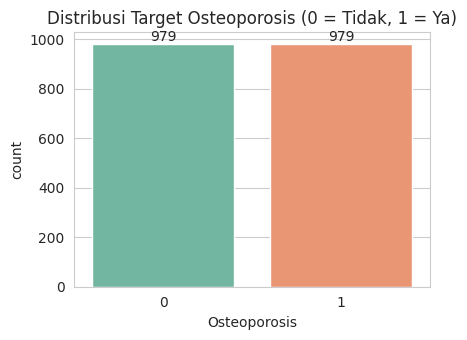

In [66]:
dist = df[target].value_counts().sort_index()
print(dist)
print((dist / len(df) * 100).round(2).astype(str) + " %")

plt.figure(figsize=(4.5, 3.5))
ax = sns.countplot(x=target, data=df, palette="Set2")
for p in ax.patches:
    ax.annotate(int(p.get_height()), (p.get_x() + p.get_width() / 2, p.get_height()),
                ha="center", va="bottom")
plt.title("Distribusi Target Osteoporosis (0 = Tidak, 1 = Ya)")
plt.tight_layout()
plt.show()


### 5.3 Distribusi Age

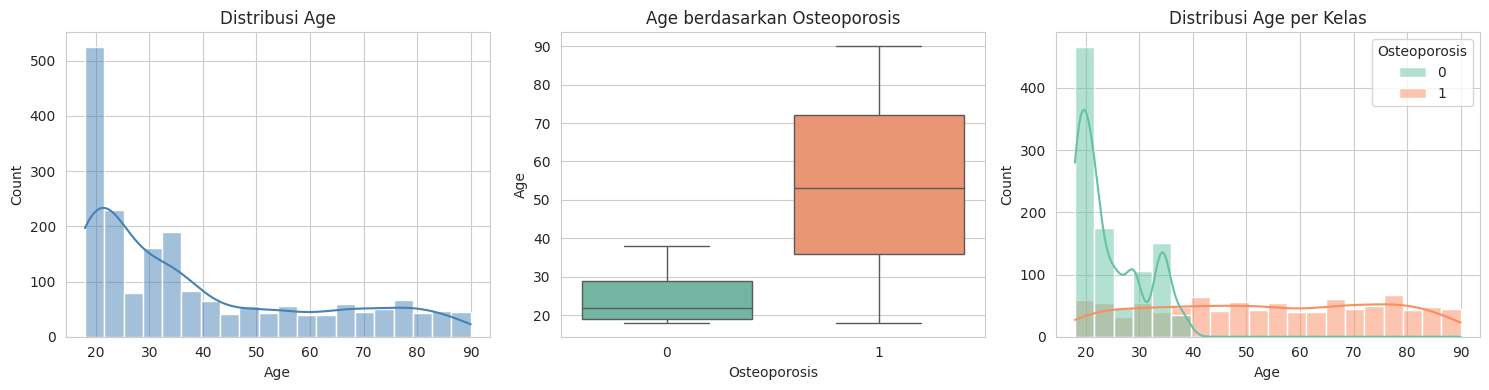

              count   mean    std   min   25%   50%   75%   max
Osteoporosis                                                   
0             979.0  24.34   6.11  18.0  19.0  22.0  29.0  38.0
1             979.0  53.86  20.96  18.0  36.0  53.0  72.0  90.0


In [67]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

sns.histplot(df["Age"], bins=20, kde=True, ax=axes[0], color="steelblue")
axes[0].set_title("Distribusi Age")

sns.boxplot(x=target, y="Age", data=df, palette="Set2", ax=axes[1])
axes[1].set_title("Age berdasarkan Osteoporosis")

sns.histplot(data=df, x="Age", hue=target, bins=20, kde=True,
             palette="Set2", ax=axes[2])
axes[2].set_title("Distribusi Age per Kelas")

plt.tight_layout()
plt.show()

print(df.groupby(target)["Age"].describe().round(2))

### 5.4 Distribusi Fitur Kategorikal terhadap Target

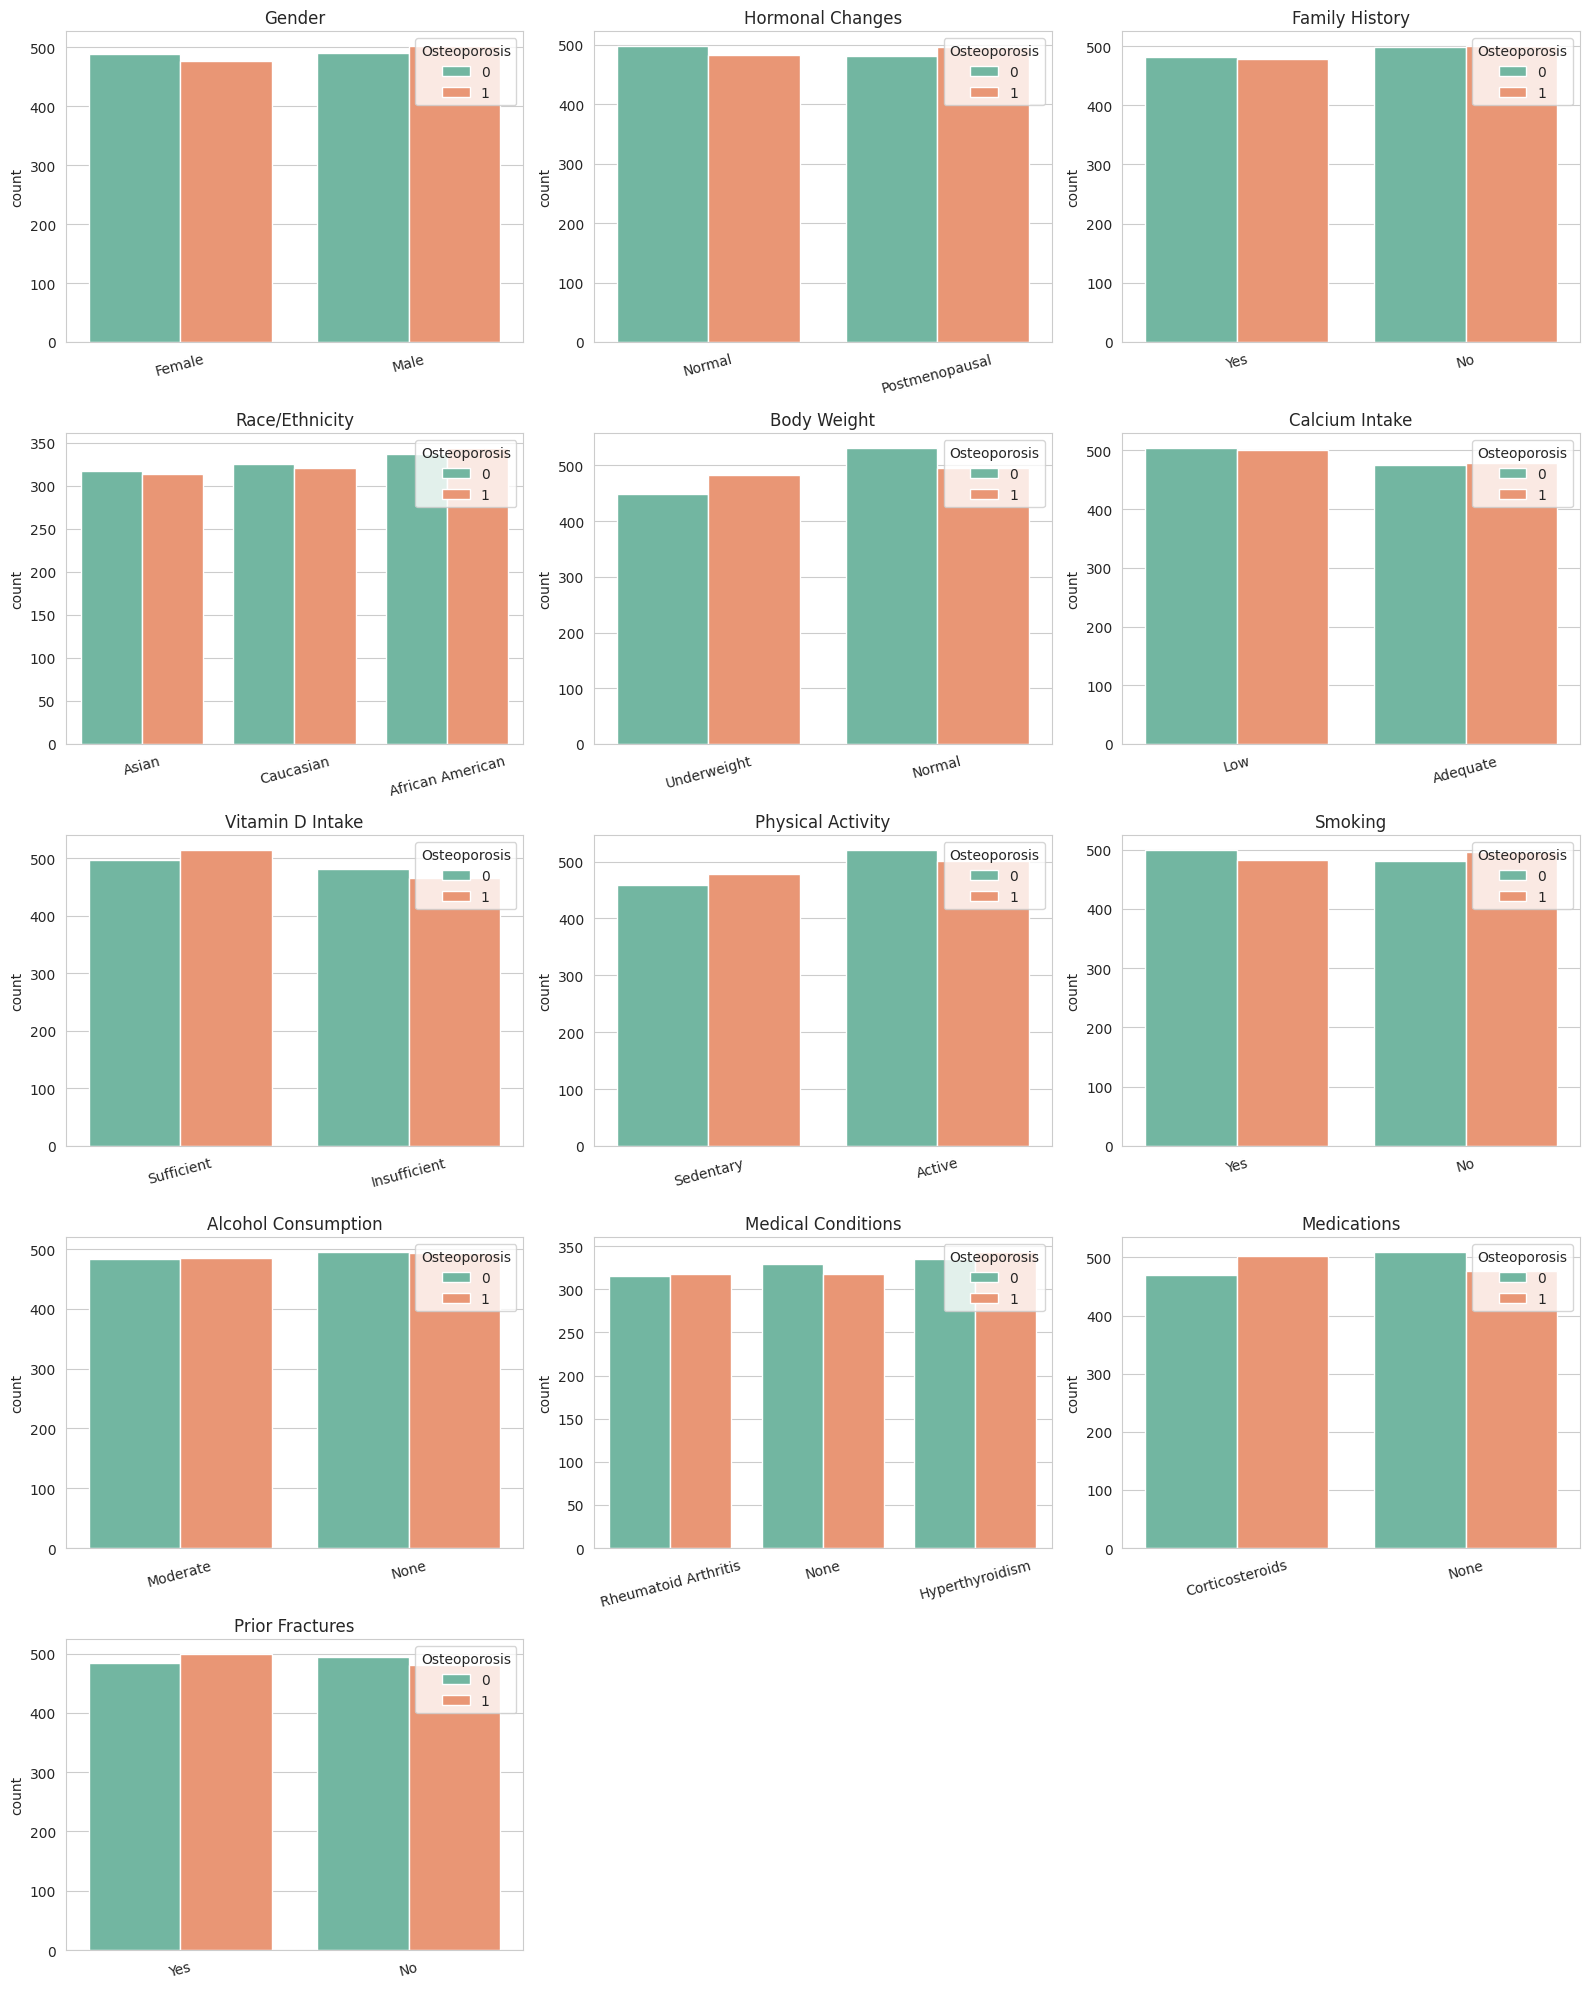

In [68]:
n = len(cat_cols)
ncols = 3
nrows = int(np.ceil(n / ncols))

fig, axes = plt.subplots(nrows, ncols, figsize=(16, 4 * nrows))
axes = axes.flatten()

for i, col in enumerate(cat_cols):
    sns.countplot(x=col, hue=target, data=df, palette="Set2", ax=axes[i])
    axes[i].set_title(col)
    axes[i].set_xlabel("")
    axes[i].tick_params(axis="x", rotation=15)

for j in range(i + 1, len(axes)):
    axes[j].axis("off")

plt.tight_layout()
plt.show()

### 5.5 Heatmap Korelasi

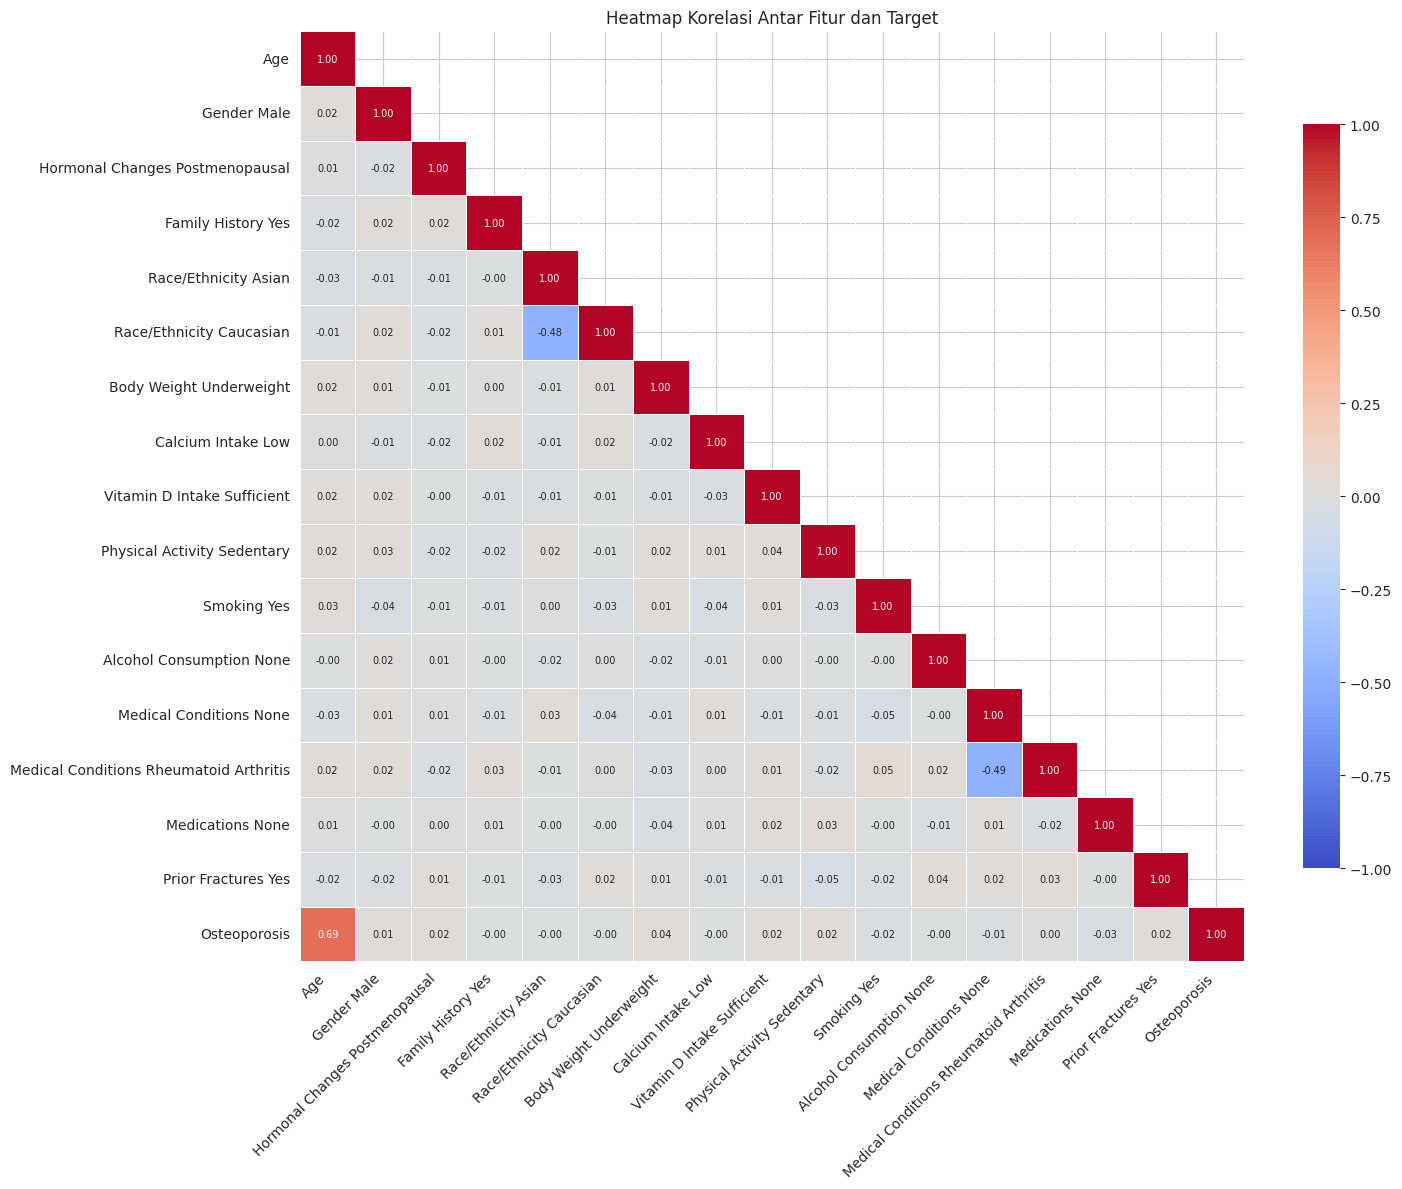

Korelasi terhadap Osteoporosis (diurutkan dari yang terkuat):
Age                                        0.691
Body Weight Underweight                    0.036
Medications None                          -0.034
Physical Activity Sedentary                0.019
Vitamin D Intake Sufficient                0.017
Smoking Yes                               -0.016
Prior Fractures Yes                        0.015
Hormonal Changes Postmenopausal            0.015
Gender Male                                0.012
Medical Conditions None                   -0.012
Race/Ethnicity Caucasian                  -0.004
Calcium Intake Low                        -0.004
Race/Ethnicity Asian                      -0.003
Medical Conditions Rheumatoid Arthritis    0.003
Family History Yes                        -0.002
Alcohol Consumption None                  -0.002
Name: Osteoporosis, dtype: float64


In [69]:
df_corr = pd.get_dummies(df, drop_first=True, dtype=int)
df_corr.columns = df_corr.columns.str.replace("_", " ")

# Taruh target di kolom terakhir supaya mudah dibaca
kolom = [c for c in df_corr.columns if c != target] + [target]
corr = df_corr[kolom].corr()

# k=1 -> diagonal (korelasi dengan diri sendiri = 1) tetap ditampilkan
mask = np.triu(np.ones_like(corr, dtype=bool), k=1)

plt.figure(figsize=(15, 12))
sns.heatmap(corr, mask=mask, annot=True, fmt=".2f", cmap="coolwarm",
            center=0, vmin=-1, vmax=1, linewidths=0.5,
            annot_kws={"size": 7}, cbar_kws={"shrink": 0.8})
plt.title("Heatmap Korelasi Antar Fitur dan Target")
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

corr_target = corr[target].drop(target).sort_values(key=abs, ascending=False)
print("Korelasi terhadap Osteoporosis (diurutkan dari yang terkuat):")
print(corr_target.round(3))

### 5.6 Proporsi Osteoporosis per Kategori

In [70]:
for col in cat_cols:
    r = df.groupby(col)[target].mean().round(3)
    print(f"{col:22s}", r.to_dict())

Gender                 {'Female': 0.494, 'Male': 0.506}
Hormonal Changes       {'Normal': 0.492, 'Postmenopausal': 0.508}
Family History         {'No': 0.501, 'Yes': 0.499}
Race/Ethnicity         {'African American': 0.505, 'Asian': 0.498, 'Caucasian': 0.497}
Body Weight            {'Normal': 0.483, 'Underweight': 0.519}
Calcium Intake         {'Adequate': 0.502, 'Low': 0.498}
Vitamin D Intake       {'Insufficient': 0.491, 'Sufficient': 0.508}
Physical Activity      {'Active': 0.491, 'Sedentary': 0.51}
Smoking                {'No': 0.508, 'Yes': 0.492}
Alcohol Consumption    {'Moderate': 0.501, 'None': 0.499}
Medical Conditions     {'Hyperthyroidism': 0.506, 'None': 0.491, 'Rheumatoid Arthritis': 0.502}
Medications            {'Corticosteroids': 0.517, 'None': 0.483}
Prior Fractures        {'No': 0.492, 'Yes': 0.508}


##**Split Data**

In [78]:
#Cell – Data Split (80% train, 20% test)
from sklearn.model_selection import train_test_split

RANDOM_STATE = 42

print("Spliting Data")
target = "Osteoporosis"

df_train, df_test = train_test_split(
    df,
    test_size=0.2,
    random_state=42,
    stratify=df[target]
)

print(f"Data train : {df_train.shape}")
print(f"Data test  : {df_test.shape}")

# Cell – Cek proporsi kelas setelah split
cek = pd.DataFrame({
    "Seluruh data": df[target].value_counts(normalize=True).round(3),
    "Train": df_train[target].value_counts(normalize=True).round(3),
    "Test": df_test[target].value_counts(normalize=True).round(3),
})
display(cek)

print("\nJumlah per kelas:")
print("Train:", df_train[target].value_counts().to_dict())
print("Test :", df_test[target].value_counts().to_dict())

Spliting Data
Data train : (1566, 15)
Data test  : (392, 15)


,Seluruh data,Train,Test
Osteoporosis,,,
0,0.5,0.5,0.5
1,0.5,0.5,0.5



Jumlah per kelas:
Train: {0: 783, 1: 783}
Test : {1: 196, 0: 196}


## **Preprocessing**

In [79]:
from sklearn.preprocessing import LabelEncoder, OneHotEncoder

# 1. Pisahkan fitur (X) dan target (y)
X_train = df_train.drop(columns=[target])
y_train = df_train[target]
X_test  = df_test.drop(columns=[target])
y_test  = df_test[target]

# 2. Tentukan kolom untuk tiap jenis encoding
ohe_cols = ["Race/Ethnicity", "Medical Conditions"]                  # kategori > 2
le_cols  = [c for c in X_train.select_dtypes(exclude="number").columns
            if c not in ohe_cols]                                    # kategori biner

# 3. Label Encoding (fit hanya di data train)
X_train_enc = X_train.copy()
X_test_enc  = X_test.copy()
label_encoders = {}

for col in le_cols:
    le = LabelEncoder()
    X_train_enc[col] = le.fit_transform(X_train[col])
    X_test_enc[col]  = le.transform(X_test[col])
    label_encoders[col] = le

# 4. One-Hot Encoding (fit hanya di data train)
ohe = OneHotEncoder(sparse_output=False, handle_unknown="ignore")
ohe.fit(X_train[ohe_cols])

def terapkan_ohe(X_enc, X_raw):
    ohe_df = pd.DataFrame(
        ohe.transform(X_raw[ohe_cols]),
        columns=ohe.get_feature_names_out(ohe_cols),
        index=X_raw.index
    )
    return pd.concat([X_enc.drop(columns=ohe_cols), ohe_df], axis=1)

X_train_enc = terapkan_ohe(X_train_enc, X_train)
X_test_enc  = terapkan_ohe(X_test_enc, X_test)

# 5. Rapikan nama kolom (hindari spasi/simbol agar aman untuk XGBoost & LightGBM)
for d in (X_train_enc, X_test_enc):
    d.columns = d.columns.str.replace(r"[^0-9a-zA-Z_]", "_", regex=True)

print("X_train :", X_train_enc.shape)
print("X_test  :", X_test_enc.shape)
print("Kolom sama antara train & test:", list(X_train_enc.columns) == list(X_test_enc.columns))

print("\nMapping Label Encoding:")
for col, le in label_encoders.items():
    print(f"  {col:20s}", dict(zip(le.classes_, le.transform(le.classes_))))

X_train_enc.head()

X_train : (1566, 18)
X_test  : (392, 18)
Kolom sama antara train & test: True

Mapping Label Encoding:
  Gender               {'Female': np.int64(0), 'Male': np.int64(1)}
  Hormonal Changes     {'Normal': np.int64(0), 'Postmenopausal': np.int64(1)}
  Family History       {'No': np.int64(0), 'Yes': np.int64(1)}
  Body Weight          {'Normal': np.int64(0), 'Underweight': np.int64(1)}
  Calcium Intake       {'Adequate': np.int64(0), 'Low': np.int64(1)}
  Vitamin D Intake     {'Insufficient': np.int64(0), 'Sufficient': np.int64(1)}
  Physical Activity    {'Active': np.int64(0), 'Sedentary': np.int64(1)}
  Smoking              {'No': np.int64(0), 'Yes': np.int64(1)}
  Alcohol Consumption  {'Moderate': np.int64(0), 'None': np.int64(1)}
  Medications          {'Corticosteroids': np.int64(0), 'None': np.int64(1)}
  Prior Fractures      {'No': np.int64(0), 'Yes': np.int64(1)}


,Age,Gender,Hormonal_Changes,Family_History,Body_Weight,Calcium_Intake,Vitamin_D_Intake,Physical_Activity,Smoking,Alcohol_Consumption,Medications,Prior_Fractures,Race_Ethnicity_African_American,Race_Ethnicity_Asian,Race_Ethnicity_Caucasian,Medical_Conditions_Hyperthyroidism,Medical_Conditions_None,Medical_Conditions_Rheumatoid_Arthritis
1473,25,0,1,0,0,1,0,1,0,0,0,0,0.0,0.0,1.0,1.0,0.0,0.0
1394,34,1,1,1,0,1,0,0,0,0,1,0,0.0,1.0,0.0,0.0,0.0,1.0
718,25,0,1,0,1,1,0,0,0,0,1,0,0.0,0.0,1.0,1.0,0.0,0.0
868,64,0,1,1,1,0,0,1,1,0,0,0,1.0,0.0,0.0,0.0,1.0,0.0
256,44,1,1,1,1,0,1,0,0,0,1,1,1.0,0.0,0.0,1.0,0.0,0.0


## **Helper: Fungsi Evaluasi Model**

In [80]:
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, confusion_matrix, classification_report)

def evaluate_model(name, model, X_train, X_test, y_train, y_test, fit=True):
    if fit:
        model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    y_proba = model.predict_proba(X_test)[:, 1]   # probabilitas kelas 1, untuk ROC-AUC

    acc  = accuracy_score(y_test, y_pred)
    prec = precision_score(y_test, y_pred, zero_division=0)
    rec  = recall_score(y_test, y_pred, zero_division=0)
    f1   = f1_score(y_test, y_pred, zero_division=0)
    auc  = roc_auc_score(y_test, y_proba)
    cm   = confusion_matrix(y_test, y_pred)

    print(f'\n{"="*55}')
    print(f'  Model : {name}')
    print(f'{"="*55}')
    print(f'  Accuracy  : {acc:.4f}')
    print(f'  Precision : {prec:.4f}')
    print(f'  Recall    : {rec:.4f}')
    print(f'  F1-Score  : {f1:.4f}')
    print(f'  ROC-AUC   : {auc:.4f}')
    print(f'\n  Classification Report:')
    print(classification_report(y_test, y_pred,
                                target_names=['Tidak Osteoporosis', 'Osteoporosis']))

    fig, ax = plt.subplots(figsize=(5, 4))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=ax,
                xticklabels=['Pred: 0', 'Pred: 1'],
                yticklabels=['Actual: 0', 'Actual: 1'])
    ax.set_title(f'Confusion Matrix — {name}', fontweight='bold')
    plt.tight_layout()
    plt.show()

    return {'model': name, 'accuracy': acc, 'precision': prec,
            'recall': rec, 'f1': f1, 'roc_auc': auc, 'fitted_model': model}

print('✅ Fungsi evaluasi siap.')

✅ Fungsi evaluasi siap.


## Latih & Evaluasi — Baseline Model
> **Pilihan model:**
> - **Random Forest** (Ensemble Bagging) — Menggabungkan banyak Decision Tree yang dilatih paralel pada sampel acak, robust terhadap overfitting
> - **XGBoost** (Ensemble Boosting) — Membangun tree secara berurutan, tiap tree memperbaiki kesalahan tree sebelumnya, dilengkapi regularisasi
> - **LightGBM** (Ensemble Boosting) — Gradient boosting dengan pertumbuhan tree leaf-wise, cepat dan efisien untuk data tabular
>
> **Catatan:** Ketiga model dilatih dengan parameter default (hanya `random_state` yang diatur) sebagai pembanding sebelum tuning Optuna.


  Model : Random Forest
  Accuracy  : 0.8291
  Precision : 0.9272
  Recall    : 0.7143
  F1-Score  : 0.8069
  ROC-AUC   : 0.8779

  Classification Report:
                    precision    recall  f1-score   support

Tidak Osteoporosis       0.77      0.94      0.85       196
      Osteoporosis       0.93      0.71      0.81       196

          accuracy                           0.83       392
         macro avg       0.85      0.83      0.83       392
      weighted avg       0.85      0.83      0.83       392



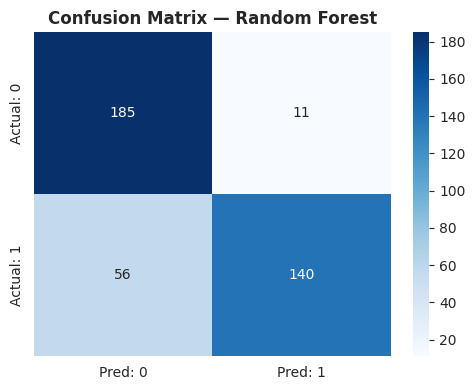

In [81]:
from sklearn.ensemble import RandomForestClassifier

rf_base = RandomForestClassifier(random_state=RANDOM_STATE)
res_rf_base = evaluate_model('Random Forest',
                             rf_base, X_train_enc, X_test_enc, y_train, y_test)


  Model : XGBoost
  Accuracy  : 0.8597
  Precision : 0.9222
  Recall    : 0.7857
  F1-Score  : 0.8485
  ROC-AUC   : 0.8881

  Classification Report:
                    precision    recall  f1-score   support

Tidak Osteoporosis       0.81      0.93      0.87       196
      Osteoporosis       0.92      0.79      0.85       196

          accuracy                           0.86       392
         macro avg       0.87      0.86      0.86       392
      weighted avg       0.87      0.86      0.86       392



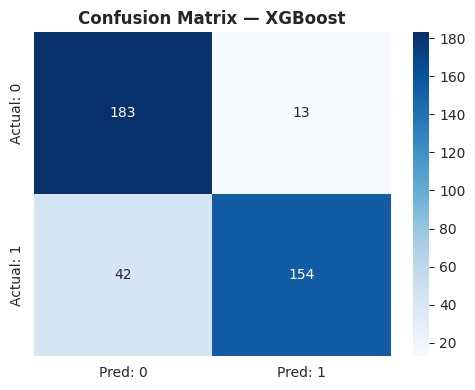

In [83]:
from xgboost import XGBClassifier

xgb_base = XGBClassifier(random_state=RANDOM_STATE, eval_metric='logloss')
res_xgb_base = evaluate_model('XGBoost',
                              xgb_base, X_train_enc, X_test_enc, y_train, y_test)


  Model : LightGBM
  Accuracy  : 0.8648
  Precision : 0.9333
  Recall    : 0.7857
  F1-Score  : 0.8532
  ROC-AUC   : 0.8849

  Classification Report:
                    precision    recall  f1-score   support

Tidak Osteoporosis       0.81      0.94      0.87       196
      Osteoporosis       0.93      0.79      0.85       196

          accuracy                           0.86       392
         macro avg       0.87      0.86      0.86       392
      weighted avg       0.87      0.86      0.86       392



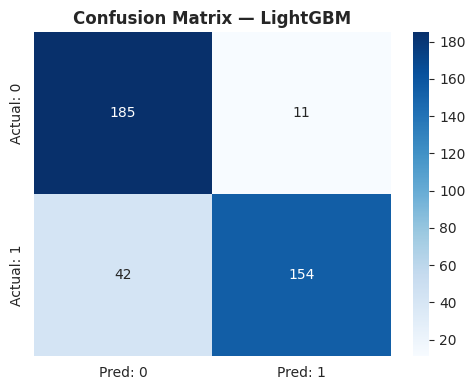

In [85]:
from lightgbm import LGBMClassifier

lgbm_base = LGBMClassifier(random_state=RANDOM_STATE, verbose=-1)
res_lgbm_base = evaluate_model('LightGBM',
                               lgbm_base, X_train_enc, X_test_enc, y_train, y_test)

## Ringkasan Performa — Baseline

In [87]:
results_baseline = pd.DataFrame([
    {k: v for k, v in r.items() if k != 'fitted_model'}
    for r in [res_rf_base, res_xgb_base, res_lgbm_base]
])
print('\n📊 Ringkasan Performa')
print(results_baseline.set_index('model').round(4).to_string())


📊 Ringkasan Performa
               accuracy  precision  recall      f1  roc_auc
model                                                      
Random Forest    0.8291     0.9272  0.7143  0.8069   0.8779
XGBoost          0.8597     0.9222  0.7857  0.8485   0.8881
LightGBM         0.8648     0.9333  0.7857  0.8532   0.8849
